# Regressão da Resistência do Concreto (com Validação Cruzada)

## Objetivo

O objetivo deste desafio é avaliar suas habilidades na resolução de um problema de regressão de ponta a ponta, incluindo análise exploratória, pré-processamento, modelagem com diferentes algoritmos, uso de redução de dimensionalidade (PCA) e, crucialmente, a aplicação de **validação cruzada** para uma avaliação robusta dos modelos.

## Problema de Negócio

Uma empresa de engenharia civil deseja otimizar a produção de concreto. A resistência à compressão do concreto é uma de suas propriedades mais importantes, mas testá-la em laboratório é um processo lento e custoso. A empresa quer desenvolver um modelo de machine learning para prever a resistência do concreto com base em seus componentes.

**Sua tarefa é construir e avaliar modelos de regressão para prever a Resistência à Compressão do Concreto (`Concrete_compressive_strength`) com base nas quantidades de cada um dos seus 8 componentes.**

## Instruções

1.  **Execute o notebook:** Siga as etapas na ordem apresentada.
2.  **Responda às perguntas:** Preencha os blocos de texto marcados com `[SUA ANÁLISE AQUI]` com suas observações e justificativas.
3.  **Código:** O código fornecido é funcional. O foco é na sua interpretação dos resultados.
4.  **Avaliação:** Serão avaliados a qualidade da sua análise, a correta aplicação e avaliação dos modelos (incluindo a interpretação dos resultados da validação cruzada) e a clareza de suas conclusões.

---

### 1. Dicionário de Dados e Configuração do Ambiente

#### Dicionário de Dados

*   **Cement (Cimento):** Quantidade de cimento em kg por m³ de mistura.
*   **Blast_Furnace_Slag (Escória de Alto Forno):** Quantidade de escória em kg por m³ de mistura.
*   **Fly_Ash (Cinza Volante):** Quantidade de cinza volante em kg por m³ de mistura.
*   **Water (Água):** Quantidade de água em kg por m³ de mistura.
*   **Superplasticizer (Superplastificante):** Quantidade de superplastificante em kg por m³ de mistura.
*   **Coarse_Aggregate (Agregado Grosso):** Quantidade de agregado grosso em kg por m³ de mistura.
*   **Fine_Aggregate (Agregado Fino):** Quantidade de agregado fino em kg por m³ de mistura.
*   **Age (Idade):** Idade do concreto em dias (tempo desde a mistura).
*   **Concrete_compressive_strength (Resistência à Compressão):** A variável alvo, medida em Megapascals (MPa).

In [197]:
# Importação de bibliotecas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configurações de visualização
%matplotlib inline
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 7)

# Bibliotecas de Machine Learning
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.decomposition import PCA
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Ignorar warnings
import warnings
warnings.filterwarnings('ignore')

In [198]:
# Carregando o dataset a partir da URL (arquivo Excel)
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/concrete/compressive/Concrete_Data.xls'
df = pd.read_excel(url)

# Renomeando colunas para facilitar o uso
df.columns = [
    'Cement',
    'Blast_Furnace_Slag',
    'Fly_Ash',
    'Water',
    'Superplasticizer',
    'Coarse_Aggregate',
    'Fine_Aggregate',
    'Age',
    'Concrete_compressive_strength'
]

df.head()

,Cement,Blast_Furnace_Slag,Fly_Ash,Water,Superplasticizer,Coarse_Aggregate,Fine_Aggregate,Age,Concrete_compressive_strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


---

### 2. Análise Exploratória de Dados (EDA)

Esta seção permanece a mesma, focada em entender os dados.

In [199]:
# visualize as colunas
print('df.head()')
display(df.head())
print('\ndf.info()')
display(df.info())
print('\ndf.describe()')
display(df.describe())
print('\ndf.skew()')
display(df.skew())

df.head()


,Cement,Blast_Furnace_Slag,Fly_Ash,Water,Superplasticizer,Coarse_Aggregate,Fine_Aggregate,Age,Concrete_compressive_strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075



df.info()
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Cement                         1030 non-null   float64
 1   Blast_Furnace_Slag             1030 non-null   float64
 2   Fly_Ash                        1030 non-null   float64
 3   Water                          1030 non-null   float64
 4   Superplasticizer               1030 non-null   float64
 5   Coarse_Aggregate               1030 non-null   float64
 6   Fine_Aggregate                 1030 non-null   float64
 7   Age                            1030 non-null   int64  
 8   Concrete_compressive_strength  1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


None


df.describe()


,Cement,Blast_Furnace_Slag,Fly_Ash,Water,Superplasticizer,Coarse_Aggregate,Fine_Aggregate,Age,Concrete_compressive_strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.165631,73.895485,54.187136,181.566359,6.203112,972.918592,773.578883,45.662136,35.817836
std,104.507142,86.279104,63.996469,21.355567,5.973492,77.753818,80.175427,63.169912,16.705679
min,102.000000,0.000000,0.000000,121.750000,0.000000,801.000000,594.000000,1.000000,2.331808
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.707115
50%,272.900000,22.000000,0.000000,185.000000,6.350000,968.000000,779.510000,28.000000,34.442774
75%,350.000000,142.950000,118.270000,192.000000,10.160000,1029.400000,824.000000,56.000000,46.136287
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.599225



df.skew()


,0
Cement,0.509517
Blast_Furnace_Slag,0.800737
Fly_Ash,0.537445
Water,0.074324
Superplasticizer,0.908113
Coarse_Aggregate,-0.040206
Fine_Aggregate,-0.252979
Age,3.269177
Concrete_compressive_strength,0.416922


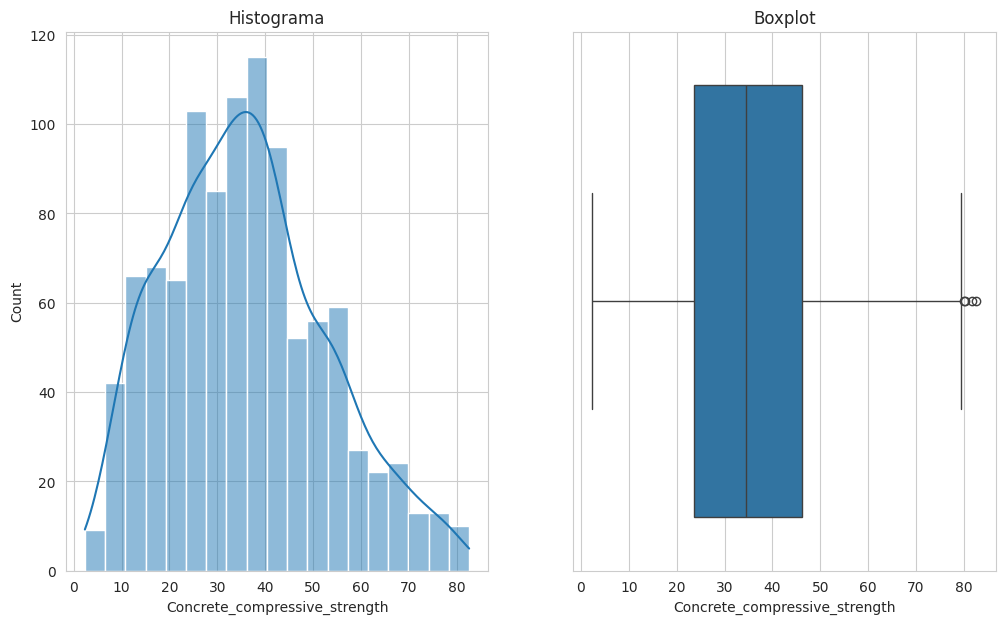

count    1030.000000
mean       35.817836
std        16.705679
min         2.331808
25%        23.707115
50%        34.442774
75%        46.136287
max        82.599225
Name: Concrete_compressive_strength, dtype: float64
Assimetria: 0.4169222822701877


In [200]:
fig, axes = plt.subplots(1, 2,)

sns.histplot(df['Concrete_compressive_strength'], kde=True, ax=axes[0])
axes[0].set_title('Histograma')

sns.boxplot(x=df['Concrete_compressive_strength'], ax=axes[1])
axes[1].set_title('Boxplot')

plt.show()

print(df['Concrete_compressive_strength'].describe())
print('Assimetria:', df['Concrete_compressive_strength'].skew())

#### **Pergunta 1:**
**O que você observa sobre a distribuição da variável alvo? Ela se assemelha a uma distribuição normal? Você identifica alguma assimetria (skewness) ou característica notável?**

> A variável alvo é a `Concrete_compressive_strength`, e sim, possui semelhança com a curva normal, como podemos verificar no histograma acima, apresentando uma leve assimetria positiva (`skewness` de aproximadamente `0,42`).

<Axes: >

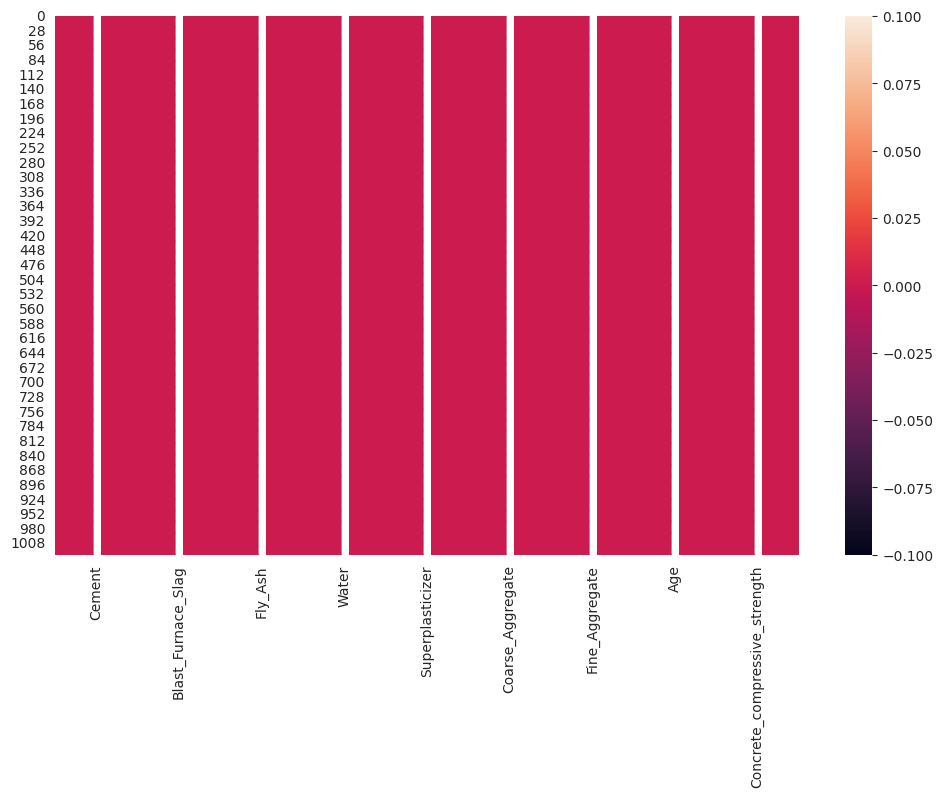

In [179]:
# analise a matriz de correlação das features a fim de identificar quais são as variáveis que tem maior correlação (negativa e positiva)
sns.heatmap(df.isnull(), annot=True)

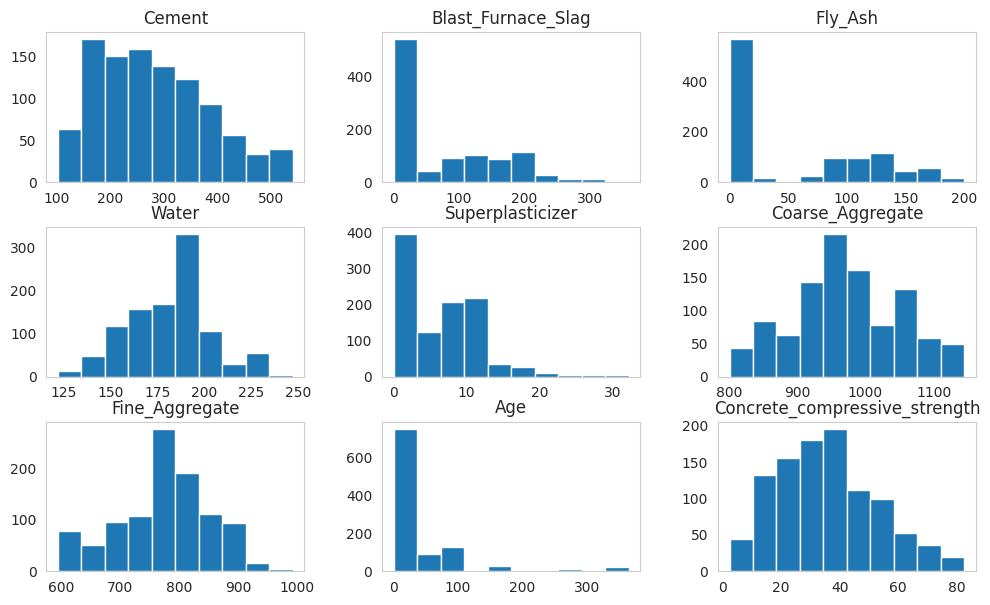

In [180]:
#plot dos valores com histogramas
fig = plt.figure()
ax = fig.gca()
df.hist(ax = ax, grid=False)
plt.show()

<Axes: >

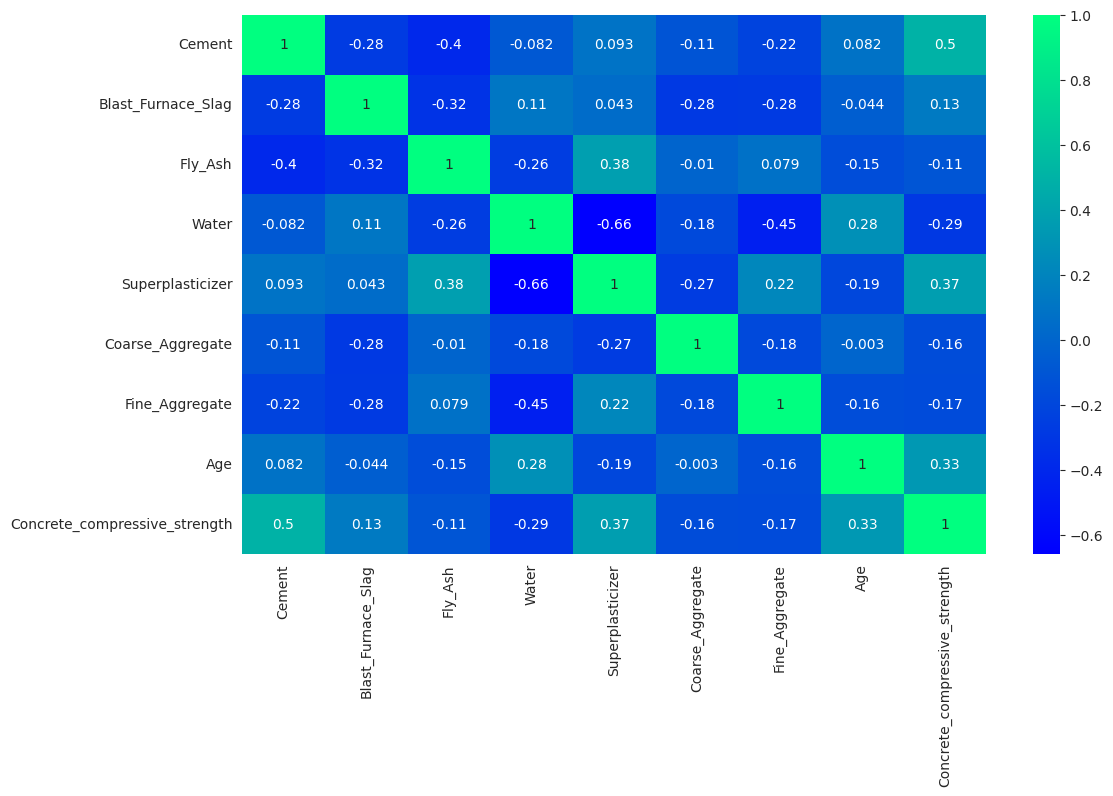

In [181]:
#plot dos valores com matriz de correlação
plt.figure()
sns.heatmap(df.corr(), annot=True, cmap='winter')

#### **Pergunta 2:**
**Com base no mapa de calor, quais são as 2 variáveis com a maior correlação com a `Concrete_compressive_strength`? Além disso, identifique um par de variáveis que apresente multicolinearidade. Por que a multicolinearidade pode ser um problema para modelos de regressão linear?**

> As variáveis com maior correlação positiva são `Cement` (`0,50`) e `Superplasticizer` (`0,37`).
Os pares que podemos observar com multicolinearidade são `Water` e `Superplasticizer`, que possuem correlação de `-0,66` (o que faz sentido, pois o uso de superplastificante reduz a necessidade de água na mistura), e outro par que também podemos observar é `Water` e `Fine_Aggregate` (`-0,45`), porém mais fraca que a outra.
Os problemas que a multicolinearidade pode ocasionar são a instabilidade nos coeficientes da regressão linear, pois pequenas variações nos dados alteram muito os valores estimados, além de comprometer a interpretação individual dos dados.

---

### 3. Pré-processamento e Divisão dos Dados

Primeiro, dividimos os dados em um conjunto de treino e um conjunto de teste. O conjunto de teste será mantido separado e só será usado na avaliação final para obter uma estimativa imparcial do desempenho do modelo.

In [182]:
# Separando features (X) e alvo (y)
# Dividindo os dados em conjuntos de treino e teste (80/20)
X_train, X_test, y_train, y_test = train_test_split(df.drop(columns=['Concrete_compressive_strength']),
                                                    df['Concrete_compressive_strength'],
                                                    test_size=0.2,
                                                    random_state=42)



In [183]:
display(pd.DataFrame(X_train))
display(pd.DataFrame(y_train))

,Cement,Blast_Furnace_Slag,Fly_Ash,Water,Superplasticizer,Coarse_Aggregate,Fine_Aggregate,Age
995,158.60,148.90,116.00,175.10,15.00,953.3,719.70,28
507,424.00,22.00,132.00,178.00,8.48,822.0,750.00,28
334,275.07,0.00,121.35,159.48,9.90,1053.6,777.50,3
848,252.00,97.00,76.00,194.00,8.00,835.0,821.00,28
294,168.88,42.22,124.25,158.33,10.83,1080.8,796.15,3
...,...,...,...,...,...,...,...,...
87,286.30,200.90,0.00,144.70,11.20,1004.6,803.70,3
330,246.83,0.00,125.08,143.30,11.99,1086.8,800.89,14
466,190.34,0.00,125.18,166.61,9.88,1079.0,798.90,100
121,475.00,118.80,0.00,181.10,8.90,852.1,781.50,28


,Concrete_compressive_strength
995,27.681082
507,62.052840
334,23.800712
848,33.398217
294,7.398077
...,...
87,24.400556
330,42.216615
466,33.563692
121,68.299493


In [184]:
display(pd.DataFrame(X_test))
display(pd.DataFrame(y_test))

,Cement,Blast_Furnace_Slag,Fly_Ash,Water,Superplasticizer,Coarse_Aggregate,Fine_Aggregate,Age
31,266.0,114.0,0.0,228.0,0.00,932.0,670.0,365
109,362.6,189.0,0.0,164.9,11.60,944.7,755.8,7
136,389.9,189.0,0.0,145.9,22.00,944.7,755.8,28
88,362.6,189.0,0.0,164.9,11.60,944.7,755.8,3
918,145.0,0.0,179.0,202.0,8.00,824.0,869.0,28
...,...,...,...,...,...,...,...,...
482,446.0,24.0,79.0,162.0,11.64,967.0,712.0,56
545,255.0,0.0,0.0,192.0,0.00,889.8,945.0,28
110,286.3,200.9,0.0,144.7,11.20,1004.6,803.7,7
514,424.0,22.0,132.0,168.0,8.92,822.0,750.0,56


,Concrete_compressive_strength
31,52.908320
109,55.895819
136,74.497882
88,35.301171
918,10.535193
...,...
482,56.144031
545,18.746163
110,37.997022
514,74.364911


##### Padronização dos Dados

In [185]:
scaler = StandardScaler()

In [186]:
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train),
                              columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test),
                             columns=X_test.columns, index=X_test.index)

In [187]:
print('Dados de Treino')
display(pd.DataFrame(X_train_scaled).describe())

print('\nDados de Teste')
display(pd.DataFrame(X_test_scaled).describe())


Dados de Treino


,Cement,Blast_Furnace_Slag,Fly_Ash,Water,Superplasticizer,Coarse_Aggregate,Fine_Aggregate,Age
count,8.240000e+02,8.240000e+02,8.240000e+02,8.240000e+02,8.240000e+02,8.240000e+02,8.240000e+02,8.240000e+02
mean,-7.114050e-17,1.616830e-16,1.509041e-17,2.802505e-16,-2.586927e-17,1.547845e-15,1.724618e-17,-3.018082e-17
std,1.000607e+00,1.000607e+00,1.000607e+00,1.000607e+00,1.000607e+00,1.000607e+00,1.000607e+00,1.000607e+00
min,-1.687494e+00,-8.555812e-01,-8.311217e-01,-2.817695e+00,-1.033338e+00,-2.193964e+00,-2.200603e+00,-7.224046e-01
25%,-8.500673e-01,-8.555812e-01,-8.311217e-01,-7.928689e-01,-1.033338e+00,-5.282882e-01,-5.600888e-01,-5.362665e-01
50%,-7.712211e-02,-6.024887e-01,-8.311217e-01,1.667534e-01,-5.406737e-03,-7.054525e-02,7.838650e-02,-2.756731e-01
75%,7.121994e-01,8.099399e-01,1.017964e+00,4.788066e-01,6.628325e-01,8.525697e-01,6.072059e-01,1.876039e-01
max,2.387984e+00,3.279030e+00,2.217596e+00,3.059698e+00,4.366236e+00,2.180024e+00,2.724337e+00,5.300197e+00



Dados de Teste


,Cement,Blast_Furnace_Slag,Fly_Ash,Water,Superplasticizer,Coarse_Aggregate,Fine_Aggregate,Age
count,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000
mean,-0.102019,-0.027362,0.080321,-0.053975,0.034266,-0.040025,0.091005,0.082788
std,0.847644,0.961826,1.000166,1.009419,1.007970,0.940945,0.948456,1.207621
min,-1.557228,-0.855581,-0.831122,-2.590108,-1.033338,-2.192692,-2.200603,-0.689313
25%,-0.788656,-0.855581,-0.831122,-0.833694,-1.033338,-0.528288,-0.401628,-0.623131
50%,-0.180591,-0.602489,-0.831122,0.126867,0.140482,-0.070545,0.111129,-0.275673
75%,0.453760,0.763348,1.017964,0.525732,0.709366,0.494004,0.709140,0.187604
max,2.387984,3.080007,2.297331,2.168117,4.366236,1.925723,2.724337,5.300197


---

### 4. Modelagem com Validação Cruzada

Agora, vamos usar a **validação cruzada de 5 folds (5-fold cross-validation)** no conjunto de treino para obter uma estimativa mais robusta do desempenho de cada modelo. Isso nos ajuda a evitar conclusões baseadas em uma única divisão de dados "sortuda" ou "azarada".

In [188]:
# PCA
pca = PCA(n_components=0.95)

In [189]:
# Regressão Linear
reg = LinearRegression()

In [190]:
# KNN
knn = KNeighborsRegressor(n_neighbors=5)

In [191]:
# Criação dos Pipeline para garantir o escalonamento correto por fold
# Sem PCA
pipeline_reg = Pipeline([("scaler", scaler), ("regressor", reg)])
pipeline_knn = Pipeline([("scaler", scaler), ("regressor", knn)])

# Com PCA
pipeline_reg_pca = Pipeline([("scaler", scaler), ("pca", pca), ("regressor", reg)])
pipeline_knn_pca = Pipeline([("scaler", scaler), ("pca", pca), ("regressor", knn)])

In [192]:
def print_metricas(scores_rmse, scores_r2 ):
    print(f"RMSE Médio: {scores_rmse.mean():.4f} (+/- {scores_rmse.std():.4f})")
    print(f"R² Médio:   {scores_r2.mean():.4f} (+/- {scores_r2.std():.4f})")


In [193]:
# Validação Sem a Aplicação do PCA
# Regressão Linear
scores_rmse_reg = -cross_val_score(pipeline_reg, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')
scores_r2_reg = cross_val_score(pipeline_reg, X_train, y_train, cv=5, scoring='r2')

# KNN
scores_rmse_knn = -cross_val_score(pipeline_knn, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')
scores_r2_knn = cross_val_score(pipeline_knn, X_train, y_train, cv=5, scoring='r2')

print("--- Regressão Linear Sem PCA ---")
print_metricas(scores_rmse_reg, scores_r2_reg)

print("\n--- KNN Sem PCA ---")
print_metricas(scores_rmse_knn, scores_r2_knn)

# Validação Com a Aplicação do PCA
# Regressão Linear com PCA
scores_rmse_reg_pca = -cross_val_score(pipeline_reg_pca, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')
scores_r2_reg_pca = cross_val_score(pipeline_reg_pca, X_train, y_train, cv=5, scoring='r2')

# KNN com PCA
scores_rmse_knn_pca = -cross_val_score(pipeline_knn_pca, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')
scores_r2_knn_pca = cross_val_score(pipeline_knn_pca, X_train, y_train, cv=5, scoring='r2')

print("\n--- Regressão Linear Com PCA ---")
print_metricas(scores_rmse_reg_pca, scores_r2_reg_pca)

print("\n--- KNN Com PCA ---")
print_metricas(scores_rmse_knn_pca, scores_r2_knn_pca)


--- Regressão Linear Sem PCA ---
RMSE Médio: 10.6652 (+/- 1.0303)
R² Médio:   0.5945 (+/- 0.0655)

--- KNN Sem PCA ---
RMSE Médio: 9.2268 (+/- 0.9852)
R² Médio:   0.6958 (+/- 0.0557)

--- Regressão Linear Com PCA ---
RMSE Médio: 11.2400 (+/- 1.2157)
R² Médio:   0.5516 (+/- 0.0691)

--- KNN Com PCA ---
RMSE Médio: 9.2605 (+/- 1.0746)
R² Médio:   0.6927 (+/- 0.0625)


#### Resultados da Validação Cruzada

In [194]:
dados_resultados = {
    "Modelo": [
        "Regressão Linear",
        "KNN",
        "Regressão Linear com PCA",
        "KNN com PCA"
    ],
    "RMSE Médio": [
        scores_rmse_reg.mean(),
        scores_rmse_knn.mean(),
        scores_rmse_reg_pca.mean(),
        scores_rmse_knn_pca.mean()
    ],
    "RMSE Std": [
        scores_rmse_reg.std(),
        scores_rmse_knn.std(),
        scores_rmse_reg_pca.std(),
        scores_rmse_knn_pca.std()
    ],
    "R² Médio": [
        scores_r2_reg.mean(),
        scores_r2_knn.mean(),
        scores_r2_reg_pca.mean(),
        scores_r2_knn_pca.mean()
    ],
    "R² Std": [
        scores_r2_reg.std(),
        scores_r2_knn.std(),
        scores_r2_reg_pca.std(),
        scores_r2_knn_pca.std()
    ]
}


df_resultados = pd.DataFrame(dados_resultados)

df_resultados = df_resultados.sort_values(by='RMSE Médio').reset_index(drop=True)

In [195]:
df_resultados

,Modelo,RMSE Médio,RMSE Std,R² Médio,R² Std
0,KNN,9.226818,0.985213,0.695822,0.055749
1,KNN com PCA,9.260453,1.074558,0.692744,0.062451
2,Regressão Linear,10.665187,1.030294,0.594534,0.065470
3,Regressão Linear com PCA,11.240015,1.215713,0.551604,0.069108


#### **Pergunta 3:**
**Com base nos resultados da validação cruzada, qual modelo apresentou o melhor desempenho médio (menor RMSE e maior R²)? Compare a estabilidade dos modelos olhando para o desvio padrão das métricas. O que um desvio padrão alto indicaria?**

> Com base no `df_resultados`, vemos que quem apresentou o melhor desempenho foi o **KNN (`k=5`) sem PCA**, apresentando o menor valor médio do RMSE (`9,2268`) e o maior R² médio (`0,6958`). Além de ser o modelo mais estável, com o menor desvio padrão (`0,9852` no RMSE e `0,0557` no R²).
Um desvio padrão muito alto indica que o desempenho do modelo varia muito a depender dos dados utilizados para treino e teste, sinalizando um modelo pouco confiável.

#### **Pergunta 4:**
**Analise o impacto do PCA. Comparando os modelos `Regressão Linear` vs. `Regressão Linear com PCA` e `KNN` vs. `KNN com PCA`, o que você pode concluir? O PCA melhorou a performance média ou a estabilidade (menor desvio padrão) dos modelos?**

> O PCA não apresentou melhoras para nenhum dos modelos. Podemos observar que os modelos tiveram uma leve piora em alguns parâmetros: houve uma piora na Regressão Linear (RMSE subiu de `10,67` para `11,24` e R² caiu de `0,59` para `0,55`) e no KNN o desempenho médio ficou praticamente igual (`9,23` vs `9,26`), porém para o desvio padrão do RMSE e do R² houve uma leve piora.
Portanto, o PCA não trouxe melhoria significativa para o uso do modelo.

---

### 5. Avaliação Final no Conjunto de Teste

Com base na validação cruzada, selecionamos o melhor modelo (aquele com o menor RMSE médio) para a avaliação final. Agora, vamos treiná-lo com **todos os dados de treino** e medir seu desempenho no **conjunto de teste**, que o modelo nunca viu antes.

In [196]:
# Selecionando o melhor modelo com base no menor RMSE da validação cruzada
melhor_modelo_final = pipeline_knn

# Treinando o melhor modelo com todos os dados de treino
melhor_modelo_final.fit(X_train, y_train)

# Fazendo previsões no conjunto de teste
y_pred_final = melhor_modelo_final.predict(X_test)

# Função para avaliar o modelo final
rmse_teste = np.sqrt(mean_squared_error(y_test, y_pred_final))
r2_teste = r2_score(y_test, y_pred_final)

print("=== AVALIAÇÃO FINAL NO CONJUNTO ===")
print(f"Modelo Selecionado: KNN (k=5)")
print(f"RMSE: {rmse_teste:.4f}")
print(f"R²:   {r2_teste:.4f}")

=== AVALIAÇÃO FINAL NO CONJUNTO ===
Modelo Selecionado: KNN (k=5)
RMSE: 8.5098
R²:   0.7190


---

### 6. Conclusão Final


#### **Pergunta 5:**
**Resuma suas descobertas. Com base nos resultados da validação cruzada e na avaliação final no conjunto de teste, qual modelo você recomendaria para a empresa de engenharia? Justifique sua escolha considerando o balanço entre desempenho, estabilidade e complexidade. Que próximos passos você sugeriria para melhorar ainda mais o modelo (ex: feature engineering e testar outros algoritmos)?**

> Como visto anteriormente, nos modelos com a aplicação do PCA só houve piora: para o caso da Regressão Linear, aumentando o RMSE em `0,57`, e para o KNN não houve mudanças significativas, no qual o RMSE apresentou um aumento de `0,03`.
Recomendo a utilização do **KNN sem PCA** pelo melhor desempenho (alcançando `RMSE = 8,5098` e `R² = 0,7190` no conjunto de teste), boa estabilidade e baixa complexidade.

> Como próximos passos, seria interessante a utilização de modelos mais fortes como o **Random Forest**, além de observar a interferência da variável `Age` no desempenho do modelo.
Sendo válido também ajustar o hiperparâmetro `k` do KNN, com o intuito de obter o melhor valor para este modelo.